# Eco-Concrete Strength Modeling (Notebook 1)

**Dataset:** Kaggle “Concrete Compressive Strength” (elikplim)  
**Goal:** Rationalize the dataset to build strong regression models for **compressive strength (MPa)** from concrete mixture compositions and **sustainability** (estimated CO₂ + cost proxies) to visualize tradeoffs.

> This notebook is designed to be a clean starting point for modeling.  
> It runs end-to-end once the dataset CSV is available locally.

---
## In this notebook:
1. Load + validate the dataset
2. Quick EDA + sanity checks
3. Train/test split with reproducible evaluation
4. Models:
    - Linear Regression (baseline)
    - Random Forest (nonlinear)
    - Gradient Boosting (strong general baseline)
5. Model evaluation metrics: **R²** and **MAE**
6. Simple **tradeoff plots**: predicted strength vs estimated CO₂ and “cost proxy”

---
## 0) Setup: establishing the dataset

Kaggle datasets usually require either:
1) **Manual download** of the CSV from Kaggle, or  
2) Kaggle API (`kaggle datasets download ...`) after setting up an API token.

**Recommended for simplicity:**  
Download the dataset zip from Kaggle and extract the CSV into:
```
./data/
```
This notebook will look for a CSV file in `./data/` automatically.



In [1]:
# Installs dependencies
!pip -q install scikit-learn pandas numpy matplotlib
# Scikit-learn is for AI model/running
# Pandas is for handling large data sets
# Numpy (100 rows or less) is for data handling and calculations
# Matplotlib is for regression and modeling
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Necessary for later steps
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance


## 1) Load the dataset

The Kaggle dataset typically contains one main CSV with columns like:
- Supplementary Cementitious Materials (SCMs)
  - **Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer**
- Aggregates
  - **Coarse Aggregate, Fine Aggregate**, (varies based on material and source)
- Other Variables
  - **Age**, Temperature, Environmental/Chemical Exposure
- Target Values
  - **Compressive Strength (MPa)**, Tensile Strength, Elasticity Modulus

We’ll auto-detect the CSV in `./data/`. If you have multiple CSVs, we’ll pick the one that looks like the concrete dataset. All the bolded variables are included in the CSV already loaded in the notebook.


In [2]:
# Connects the notebook to a google drive path
from google.colab import drive
drive.mount('/content/drive')
DATA_DIR = "/content/drive/MyDrive/Indigo Research Worksheets/data"

if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(
        f"Missing folder: {DATA_DIR}/\n"
        "Create it and place the Kaggle CSV inside. Example:\n"
        "  data/Concrete_Data.csv"
    )

csv_candidates = glob.glob(os.path.join(DATA_DIR, "*.csv"))
if len(csv_candidates) == 0:
    raise FileNotFoundError(
        "No CSV files found in ./data/\n"
        "Download the Kaggle dataset and extract the CSV into ./data/"
    )

# Heuristic: choose the CSV with the most columns and rows (often the main dataset)
best = None
best_score = -1
for fp in csv_candidates:
    try:
        df_tmp = pd.read_csv(fp)
        score = df_tmp.shape[0] * df_tmp.shape[1]
        if score > best_score:
            best_score = score
            best = fp
    except Exception:
        continue

# If a suitable CSV cannot be found
if best is None:
    raise RuntimeError("Could not read any CSV candidates in ./data/.")

# Prints the results for viewing
df = pd.read_csv(best)
print("Loaded:", best)
print("Shape:", df.shape)
df.head()


Mounted at /content/drive
Loaded: /content/drive/MyDrive/Indigo Research Worksheets/data/concrete_data.csv
Shape: (1030, 9)


,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


## 2) Clean column names + identify target

Different versions of the dataset sometimes have slightly different column names.
We’ll normalize names (lowercase, underscores) and try to auto-detect the target column.

If auto-detection fails, set `TARGET_COL` manually.


In [3]:
# Normalizes the dataset
def normalize_col(c: str) -> str:
    c = c.strip().lower()
    c = c.replace(" ", "_")
    c = c.replace("-", "_")
    c = c.replace("(", "").replace(")", "")
    c = c.replace("__", "_")
    return c

df = df.copy()
df.columns = [normalize_col(c) for c in df.columns]

# Try to auto-detect target column
possible_targets = [c for c in df.columns if "strength" in c or "compressive" in c]
print("Possible target columns:", possible_targets)

TARGET_COL = None
for c in possible_targets:
    # Prefer something that explicitly indicates MPa if present
    if "mpa" in c:
        TARGET_COL = c
        break
if TARGET_COL is None and len(possible_targets) == 1:
    TARGET_COL = possible_targets[0]

if TARGET_COL is None:
    # Fallback: common name used in this dataset
    if "concrete_compressive_strength" in df.columns:
        TARGET_COL = "concrete_compressive_strength"
    else:
        raise ValueError(
            "Could not auto-detect target column.\n"
            "Please set TARGET_COL manually after inspecting df.columns."
        )

print("Using TARGET_COL =", TARGET_COL)

# Basic missing-value check
missing = df.isna().sum().sort_values(ascending=False)
print("\nTop missing-value columns:")
print(missing.head(10))

df.describe(include='all').T.head(20)


Possible target columns: ['concrete_compressive_strength']
Using TARGET_COL = concrete_compressive_strength

Top missing-value columns:
cement                           0
blast_furnace_slag               0
fly_ash                          0
water                            0
superplasticizer                 0
coarse_aggregate                 0
fine_aggregate                   0
age                              0
concrete_compressive_strength    0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.167864,104.506364,102.00,192.375,272.900,350.000,540.0
blast_furnace_slag,1030.0,73.895825,86.279342,0.00,0.000,22.000,142.950,359.4
fly_ash,1030.0,54.188350,63.997004,0.00,0.000,0.000,118.300,200.1
water,1030.0,181.567282,21.354219,121.80,164.900,185.000,192.000,247.0
superplasticizer,1030.0,6.204660,5.973841,0.00,0.000,6.400,10.200,32.2
coarse_aggregate,1030.0,972.918932,77.753954,801.00,932.000,968.000,1029.400,1145.0
fine_aggregate,1030.0,773.580485,80.175980,594.00,730.950,779.500,824.000,992.6
age,1030.0,45.662136,63.169912,1.00,7.000,28.000,56.000,365.0
concrete_compressive_strength,1030.0,35.817961,16.705742,2.33,23.710,34.445,46.135,82.6


## 3) Quick EDA (sanity checks)

Goals:
- Confirm numeric columns
- Check target distribution
- Look for obvious outliers


Numeric columns: ['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age', 'concrete_compressive_strength']
Non-numeric columns: []


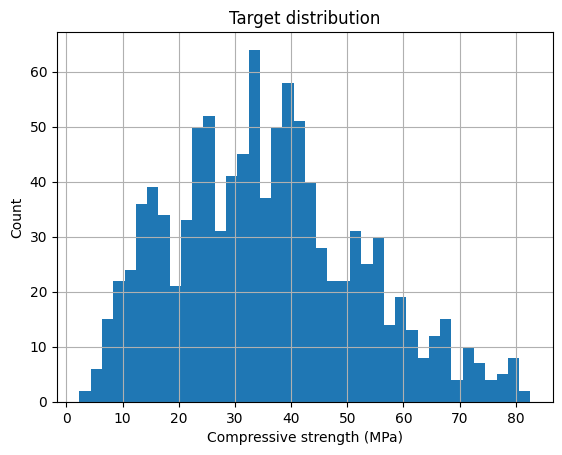

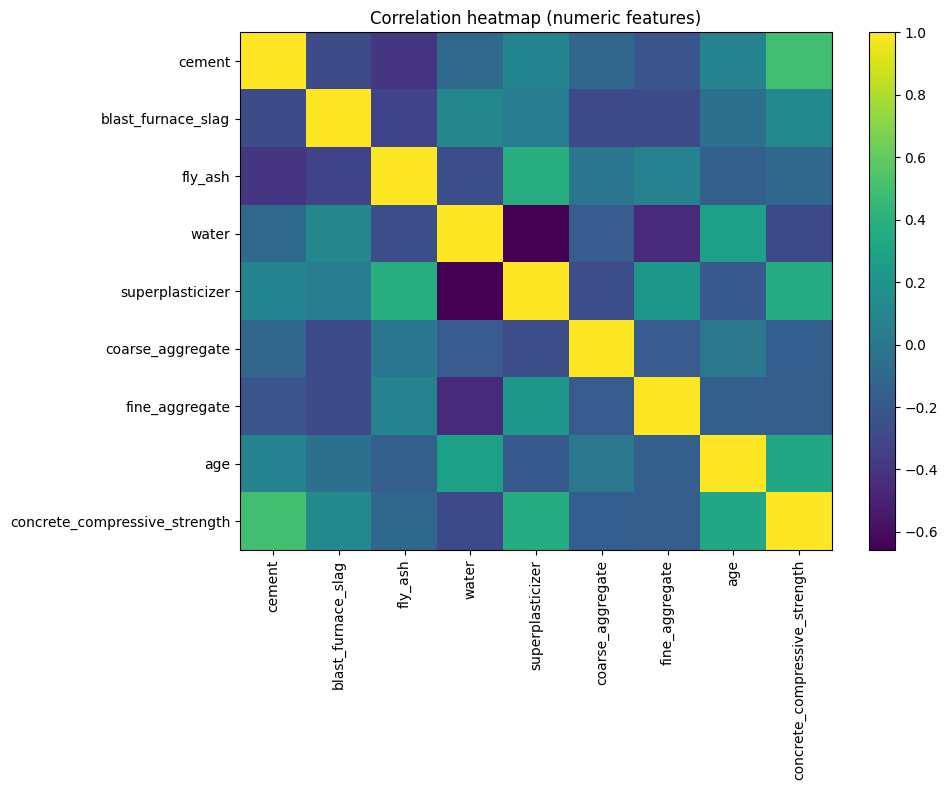

In [4]:
# Ensure numeric columns exist
for c in df.columns:
    if c == TARGET_COL:
        continue
    # If a column is object but should be numeric, try coercion
    if df[c].dtype == "object":
        df[c] = pd.to_numeric(df[c], errors="coerce")

# Drop rows where target is missing
df = df.dropna(subset=[TARGET_COL]).reset_index(drop=True)

numeric_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
print("Numeric columns:", numeric_cols)
print("Non-numeric columns:", [c for c in df.columns if c not in numeric_cols])

# Target distribution graph
    # Histogram graph shows how MPa varies and shows the mean/median
    # Can be used to improve clustering around a specific MPa
plt.figure()
df[TARGET_COL].hist(bins=40)
plt.xlabel("Compressive strength (MPa)")
plt.ylabel("Count")
plt.title("Target distribution")
plt.show()

# Correlations heatmap (quick glance)
    # Correlation heatmap represents the relationship between materials
    # Yellow is positive correlation (increases together)
    # Purple is negative correlation (decreases together)
corr = df[numeric_cols].corr(numeric_only=True)
plt.figure(figsize=(10, 8))
plt.imshow(corr, aspect="auto")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation heatmap (numeric features)")
plt.tight_layout()
plt.show()

## 4) Train/test split

We’ll define features **X** and target **y**.


In [5]:
# Features = all numeric columns except the target
feature_cols = [c for c in numeric_cols if c != TARGET_COL]
X = df[feature_cols].copy()
y = df[TARGET_COL].copy()

# Train/test split
    # Indicates 20% is for out of box testing and not machine learning
    # random_state variable ensures repeatability
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Prints results for viewing
print("Features:", feature_cols)
print("Train:", X_train.shape, "Test:", X_test.shape)


Features: ['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate', 'age']
Train: (824, 8) Test: (206, 8)


## 5) Train baseline + stronger models

### Models
- **Linear Regression** (baseline; interpretable)
- **Random Forest** (handles nonlinear interactions well)
- **Gradient Boosting** (often a strong default for tabular regression)

We’ll evaluate with:
- **R²** (higher is better)
- **MAE** in MPa (lower is better)


In [6]:
# Trains and evaluates machine learning models
def evaluate(name, model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    r2 = r2_score(y_test, pred)
    mae = mean_absolute_error(y_test, pred)
    return {"model": name, "r2": r2, "mae": mae, "fitted_model": model, "y_pred": pred}

models = []

# Linear Regression with standardization (baseline)
lin = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LinearRegression())
])
# Stores as a model
models.append(("LinearRegression", lin))

# Creates Random Forest Regression
rf = RandomForestRegressor(
# Number of trees
    n_estimators=400,
# Ensures repeatability
    random_state=42,
# Determines memory consumption ("-1" -> utilizes all CPU cores available)
    n_jobs=-1,
# Minimum number of samples in final prediction of each tree
    min_samples_leaf=1
)
# Stores as a model
models.append(("RandomForest", rf))
# Creates Gradient Boosting Regression
gbr = GradientBoostingRegressor(
# Ensures repeatability
    random_state=42
)
# Stores as a model
models.append(("GradientBoosting", gbr))

results = []
fitted = {}

# Displays a ranked comparison of each model and their values
for name, m in models:
    out = evaluate(name, m, X_train, y_train, X_test, y_test)
    results.append({k: out[k] for k in ["model", "r2", "mae"]})
    fitted[name] = out

results_df = pd.DataFrame(results).sort_values(by="r2", ascending=False)
results_df


,model,r2,mae
2,GradientBoosting,0.882889,4.135014
1,RandomForest,0.881778,3.787604
0,LinearRegression,0.627553,7.745559


## 6) Visualize predictions

We’ll plot predicted vs actual for the best-performing model (by R²).


Best model: GradientBoosting
R²: 0.8828886141958622
MAE: 4.135014150874571 MPa


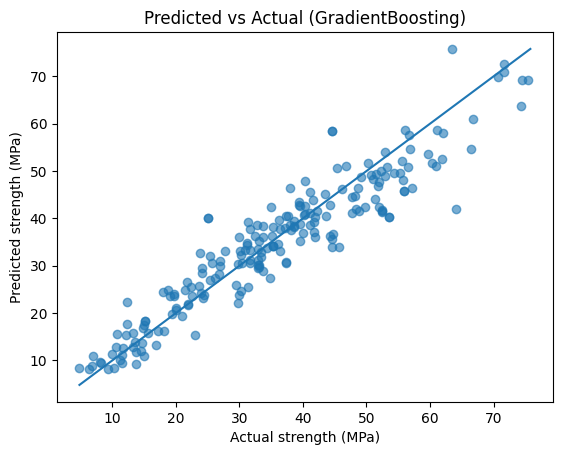

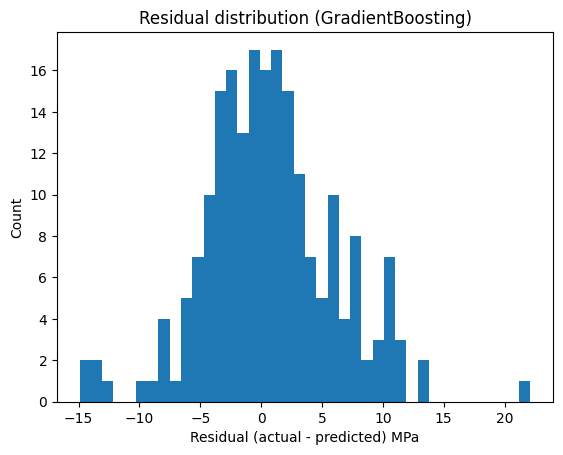

In [7]:
# Defines best model and pulls its results
best_name = results_df.iloc[0]["model"]
best = fitted[best_name]
y_pred = best["y_pred"]

# Prints results
print("Best model:", best_name)
print("R²:", best["r2"])
print("MAE:", best["mae"], "MPa")

# Plots and labels x and y-axis
plt.figure()
plt.scatter(y_test, y_pred, alpha=0.6)
plt.xlabel("Actual strength (MPa)")
plt.ylabel("Predicted strength (MPa)")
plt.title(f"Predicted vs Actual ({best_name})")
# Places 45-degree line
mn = min(y_test.min(), y_pred.min())
mx = max(y_test.max(), y_pred.max())
plt.plot([mn, mx], [mn, mx])
plt.show()

# Residuals (Negative = Overpredicted, Positive = Underpredicted)
resid = y_test.values - y_pred
# Creates and shows histogram of residuals
plt.figure()
plt.hist(resid, bins=40)
plt.xlabel("Residual (actual - predicted) MPa")
plt.ylabel("Count")
plt.title(f"Residual distribution ({best_name})")
plt.show()


## 7) Feature importance (permutation importance)

Permutation importance answers if shuffling a feature will degrade a model's performance. This is a good, model-agnostic way to interpret the trained model.


In [8]:
# Defines the best model
best_model = best["fitted_model"]

# Measures importance of each variable using "r2" as a scoring metric
perm = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=20,
    random_state=42,
    scoring="r2"
)

# Sorts variables and provides mean + STD for each
importances = pd.DataFrame({
    "feature": feature_cols,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

# Displays 15 most relevant variables
importances.head(15)


,feature,importance_mean,importance_std
7,age,0.798450,0.042507
0,cement,0.436112,0.040973
3,water,0.227918,0.017233
1,blast_furnace_slag,0.143060,0.017756
4,superplasticizer,0.054934,0.006697
6,fine_aggregate,0.039867,0.007553
5,coarse_aggregate,0.014180,0.003916
2,fly_ash,0.000772,0.002573


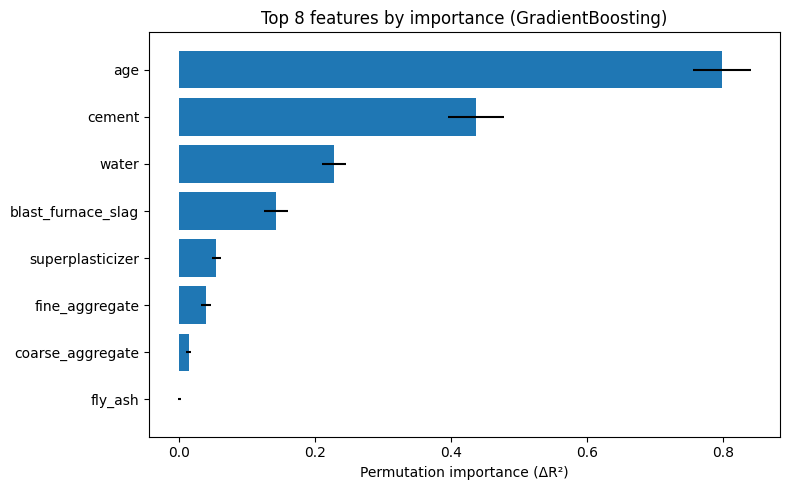

In [9]:
# Number of variables considered
top_k = min(12, len(feature_cols))
# Takes variables and reverses the horizontal bar order
top = importances.head(top_k).iloc[::-1]

# Plots results of previous code
plt.figure(figsize=(8, 5))
plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
plt.xlabel("Permutation importance (ΔR²)")
plt.title(f"Top {top_k} features by importance ({best_name})")
plt.tight_layout()
plt.show()


## 8) Sustainability layer (CO₂ + cost proxies)

**Important:** The Kaggle dataset does *not* include CO₂ emissions or cost.  
To determine sustainability, we create *proxies* from mixture composition.

### How to use this section responsibly
- Treat these as **scenario estimates**, not ground-truth lifecycle assessments.
- Use **literature/CSI** sources to justify the factors you pick.

### Simple proxy approach
Estimate emissions as:
- `CO2_kg = sum_i (mass_i_kg_per_m3 * factor_i_kgCO2_per_kg)`

The current values are defined by literature results and market value estimations as of June 2026.


In [10]:
# Note
    # Current values should be defined or replaced by relevant literature results
    # Current calculations uses GGBFS and natural aggregate data
# CO₂ measured in kg relative to m^3
CO2_FACTORS = {
    "cement": 2614.5,
    "blast_furnace_slag": 393.6586,
    "fly_ash": 314.65,
    "water": 0.196,
    "superplasticizer": 300,
    "coarse_aggregate": 19.05,
    "fine_aggregate": 6.76,
}

# Cost measured in US dollars relative to m^3
COST_FACTORS = {
    "cement": 226.80,
    "blast_furnace_slag": 148.65,
    "fly_ash": 273.42,
    "water": 9.60,
    "superplasticizer": 963.84,
    "coarse_aggregate": 24.38,
    "fine_aggregate": 20.80,
}

# Map dataset feature names to  factor keys.
# Adjust these if your dataset uses different names.
FEATURE_MAP = {
    "cement": "cement",
    "blast_furnace_slag": "blast_furnace_slag",
    "fly_ash": "fly_ash",
    "water": "water",
    "superplasticizer": "superplasticizer",
    "coarse_aggregate": "coarse_aggregate",
    "fine_aggregate": "fine_aggregate",
    # "age" intentionally excluded from CO2/cost
}

# Check which mapped features exist
missing_features = [f for f in FEATURE_MAP if f not in df.columns]
if missing_features:
    print("WARNING: These expected features are missing from the dataset columns:")
    print(missing_features)
    print("Update FEATURE_MAP to match df.columns.")
else:
    print("All key mixture features found.")


All key mixture features found.


In [11]:
# Inserts factors from previous code and calculates using Panda
def compute_proxy(df_in: pd.DataFrame, factors: dict, feature_map: dict) -> pd.Series:
    total = np.zeros(len(df_in), dtype=float)
    for col, key in feature_map.items():
        # Helps with missing columns/factors
        if col not in df_in.columns:
            continue
        if key not in factors:
            continue
        # Takes column values and corresponding factor and adds result to total
        total += df_in[col].values * float(factors[key])
    return pd.Series(total, index=df_in.index)

# Use the full dataframe (same rows as modeling)
df_proxy = df.copy()

# Computes and stores CO2 and Cost proxy
df_proxy["co2_proxy_kg"] = compute_proxy(df_proxy, CO2_FACTORS, FEATURE_MAP)
df_proxy["cost_proxy_units"] = compute_proxy(df_proxy, COST_FACTORS, FEATURE_MAP)

# Add predicted strength using best model (for tradeoff plots)
df_proxy["pred_strength_mpa"] = best_model.predict(df_proxy[feature_cols])

df_proxy[[TARGET_COL, "pred_strength_mpa", "co2_proxy_kg", "cost_proxy_units"]].describe().T


,count,mean,std,min,25%,50%,75%,max
concrete_compressive_strength,1030.0,35.817961,16.705742,2.330000,23.710000,34.445000,46.135000,8.260000e+01
pred_strength_mpa,1030.0,35.673920,15.537152,4.120545,24.977019,35.316025,45.078988,8.022292e+01
co2_proxy_kg,1030.0,806913.966899,257342.614450,350211.667800,593878.622000,774754.220350,983831.048800,1.437439e+06
cost_proxy_units,1030.0,137103.247764,21940.533638,88938.910000,122040.221000,136063.306000,150546.604500,1.944061e+05


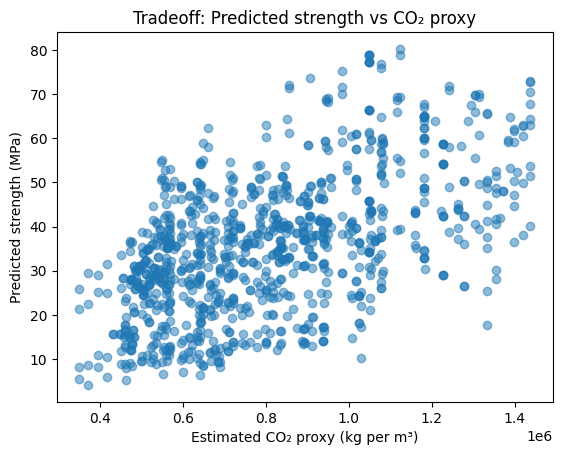

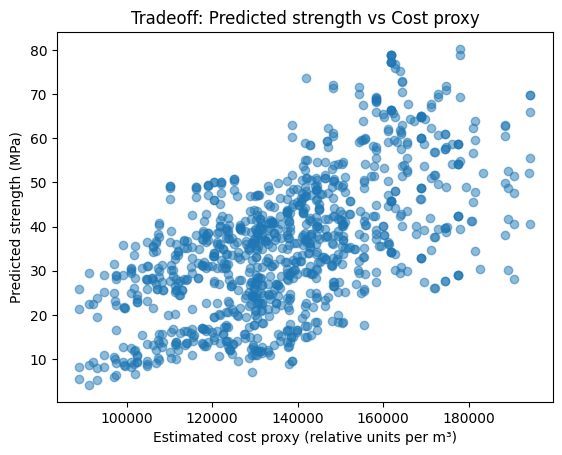

In [12]:
# Strength vs CO2 proxy
plt.figure()
plt.scatter(df_proxy["co2_proxy_kg"], df_proxy["pred_strength_mpa"], alpha=0.5)
plt.xlabel("Estimated CO₂ proxy (kg per m³)")
plt.ylabel("Predicted strength (MPa)")
plt.title("Tradeoff: Predicted strength vs CO₂ proxy")
plt.show()

# Strength vs Cost proxy
plt.figure()
plt.scatter(df_proxy["cost_proxy_units"], df_proxy["pred_strength_mpa"], alpha=0.5)
plt.xlabel("Estimated cost proxy (relative units per m³)")
plt.ylabel("Predicted strength (MPa)")
plt.title("Tradeoff: Predicted strength vs Cost proxy")
plt.show()


## 9) Identify “better” mixtures (simple Pareto idea)

A mixture is **Pareto-optimal** if no other mixture is **higher strength** AND **lower emissions** at the same time. This isn’t a perfect optimization (because this dataset is observational), but it’s a clean way to show *tradeoffs*.


Pareto candidates: 24


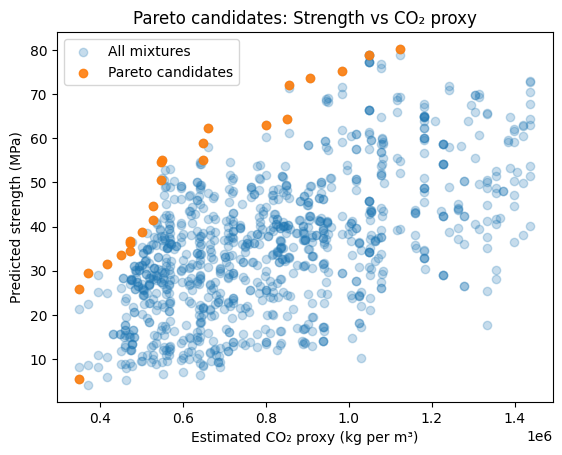

,pred_strength_mpa,co2_proxy_kg,cost_proxy_units,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate
652,5.388833,350211.66780,88938.910,102.0,153.0,0.0,192.0,0.0,887.0,942.0
653,25.870791,350211.66780,88938.910,102.0,153.0,0.0,192.0,0.0,887.0,942.0
659,29.557537,370732.34264,91189.316,108.3,162.4,0.0,203.5,0.0,938.2,849.0
650,31.505015,416633.78854,97099.011,122.6,183.9,0.0,203.5,0.0,958.2,800.1
683,33.594237,449837.81400,101802.972,133.0,200.0,0.0,192.0,0.0,927.4,839.2
16,34.494402,472853.93684,106941.170,139.6,209.4,0.0,192.0,0.0,1047.0,806.9
23,36.303448,472853.93684,106941.170,139.6,209.4,0.0,192.0,0.0,1047.0,806.9
66,36.696405,472853.93684,106941.170,139.6,209.4,0.0,192.0,0.0,1047.0,806.9
458,38.695684,501855.10880,121512.840,165.0,0.0,143.6,163.8,0.0,1005.6,900.9
297,41.467968,526555.01672,133405.672,168.9,42.2,124.3,158.3,10.8,1080.8,796.2


In [13]:
# Simple Pareto front for max strength and minimum CO₂
points = df_proxy[["pred_strength_mpa", "co2_proxy_kg"]].to_numpy()

# Sort by ascending CO₂ values, then keep points with maximum strength
order = np.argsort(points[:, 1])
sorted_pts = points[order]

# Stores and tracks best scores
pareto_idx = []
best_strength = -np.inf
# Loops through sorted_pts and updates best strength found
for i, (s, c) in enumerate(sorted_pts):
    if s > best_strength:
        best_strength = s
        pareto_idx.append(order[i])

# Selects optimal points and sorts by CO₂
df_pareto = df_proxy.iloc[pareto_idx].sort_values("co2_proxy_kg")
print("Pareto candidates:", df_pareto.shape[0])

# Plots and graphs results
plt.figure()
plt.scatter(df_proxy["co2_proxy_kg"], df_proxy["pred_strength_mpa"], alpha=0.25, label="All mixtures")
plt.scatter(df_pareto["co2_proxy_kg"], df_pareto["pred_strength_mpa"], alpha=0.9, label="Pareto candidates")
plt.xlabel("Estimated CO₂ proxy (kg per m³)")
plt.ylabel("Predicted strength (MPa)")
plt.title("Pareto candidates: Strength vs CO₂ proxy")
plt.legend()
plt.show()

# Forms a table
df_pareto[[
    "pred_strength_mpa", "co2_proxy_kg", "cost_proxy_units"
] + [c for c in FEATURE_MAP.keys() if c in df_pareto.columns]].head(15)
